# Customer Segmentation Modeling



## 1. Load Dataset

Tahap ini menggunakan dataset hasil Feature Engineering dan Preprocessing dari notebook sebelumnya. Dataset berisi identitas pelanggan serta tiga fitur RFM yang telah ditransformasi dan distandardisasi.

Model K-Means akan menggunakan Recency, Frequency, dan Monetary untuk mengelompokkan pelanggan berdasarkan kemiripan perilaku pembelian. Kolom `CustomerID` tetap disimpan untuk mengidentifikasi pelanggan pada setiap segmen, tetapi tidak digunakan sebagai fitur model.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

project_path = '/content/drive/MyDrive/ecommerce-sales-customer-analytics'
file_path = f'{project_path}/data/rfm_modeling.csv'

rfm_modeling = pd.read_csv(file_path)

print('Ukuran dataset:', rfm_modeling.shape)
print('Kolom:', rfm_modeling.columns.tolist())
print('Jumlah nilai kosong:', rfm_modeling.isnull().sum().sum())

display(rfm_modeling.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ukuran dataset: (4338, 4)
Kolom: ['CustomerID', 'Recency', 'Frequency', 'Monetary']
Jumlah nilai kosong: 0


,CustomerID,Recency,Frequency,Monetary
0,12346.0,2.329388,-0.955214,3.707716
1,12347.0,-0.900588,1.074425,1.414903
2,12348.0,-0.170593,0.386304,0.720024
3,12349.0,-0.740589,-0.955214,0.702287
4,12350.0,2.179389,-0.955214,-0.614514


## 2. Menentukan Jumlah Cluster
Menentukan jumlah cluster yang sesuai untuk mengelompokkan pelanggan menggunakan algoritma K-Means. Jumlah cluster yang terlalu sedikit dapat menggabungkan pelanggan dengan karakteristik berbeda, sedangkan jumlah cluster yang terlalu banyak dapat menghasilkan kelompok yang sulit diinterpretasikan.

Untuk menentukan jumlah cluster, digunakan dua metode evaluasi, yaitu Elbow Method dan Silhouette Score. Elbow Method digunakan untuk mengamati perubahan inertia ketika jumlah cluster bertambah, sedangkan Silhouette Score digunakan untuk menilai seberapa baik pelanggan berada dalam cluster masing-masing dibandingkan dengan cluster lain.


### 2.1 Menyiapkan Fitur untuk Evaluasi

Kolom `CustomerID` merupakan identitas pelanggan, sehingga tidak digunakan dalam perhitungan K-Means. Model hanya menggunakan tiga fitur RFM yang telah distandardisasi, yaitu Recency, Frequency, dan Monetary.

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = rfm_modeling[['Recency', 'Frequency', 'Monetary']]

print('Ukuran fitur:', X.shape)
print('Jumlah nilai kosong:', X.isnull().sum().sum())

Ukuran fitur: (4338, 3)
Jumlah nilai kosong: 0


### 2.2 Evaluasi Kandidat Jumlah Cluster

Beberapa kandidat jumlah cluster akan diuji untuk membandingkan kualitas pengelompokan pelanggan. Elbow Method menggunakan inertia, yaitu jumlah kuadrat jarak pelanggan terhadap pusat cluster masing-masing. Inertia akan semakin kecil ketika jumlah cluster bertambah.

Silhouette Score melengkapi evaluasi tersebut dengan menilai kekompakan pelanggan dalam cluster dan pemisahannya dari cluster lain. Nilainya berkisar dari -1 sampai 1, dengan nilai yang lebih tinggi umumnya menunjukkan pemisahan cluster yang lebih baik.

In [15]:
k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X, labels))

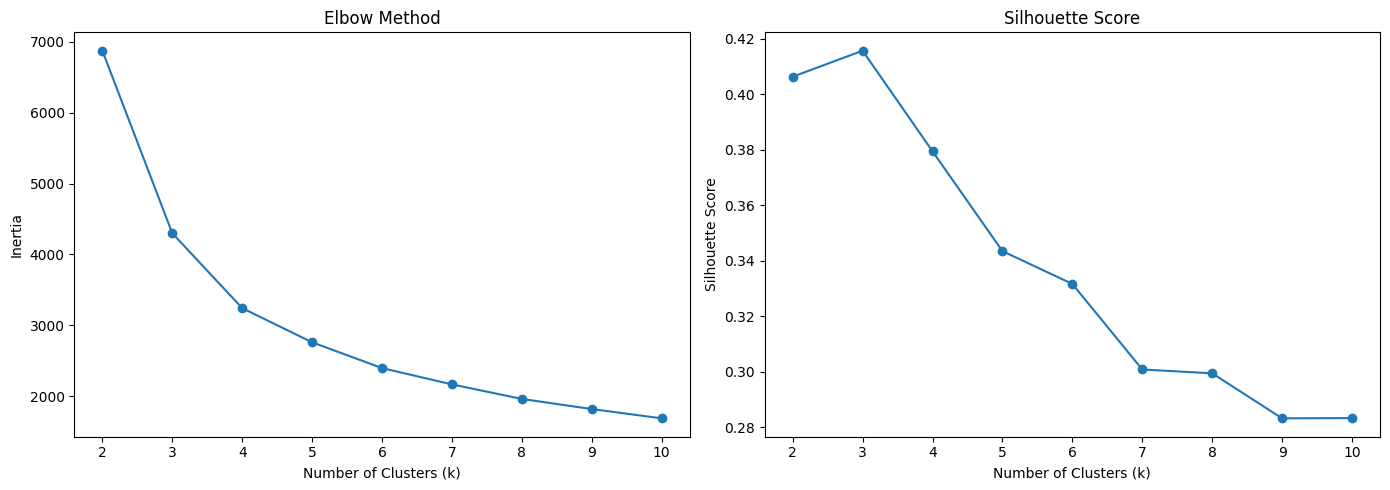

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_values), inertias, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].set_xticks(list(k_values))

axes[1].plot(list(k_values), silhouette_scores, marker='o')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(k_values))

plt.tight_layout()
plt.show()

In [17]:
evaluation_results = pd.DataFrame({
    'k': list(k_values),
    'Inertia': inertias,
    'Silhouette_Score': silhouette_scores
})

display(evaluation_results.round(4))

,k,Inertia,Silhouette_Score
0,2,6874.0473,0.4063
1,3,4299.2010,0.4157
2,4,3242.9348,0.3794
3,5,2760.6831,0.3435
4,6,2396.8027,0.3316
5,7,2167.0871,0.3008
6,8,1961.6506,0.2995
7,9,1819.2521,0.2832
8,10,1688.1669,0.2833


## 3. Membangun Model K-Means

Berdasarkan hasil evaluasi menggunakan Elbow Method dan Silhouette Score, jumlah cluster sebanyak 3 dipilih sebagai kandidat utama untuk membangun model K-Means. Jumlah ini menghasilkan Silhouette Score tertinggi, yaitu 0,4157, serta masih sesuai dengan pola penurunan inertia.

Model akan digunakan untuk mengelompokkan pelanggan berdasarkan fitur Recency, Frequency, dan Monetary yang telah melalui transformasi dan standardisasi. Hasil pengelompokan selanjutnya akan diperiksa untuk mengetahui karakteristik setiap segmen pelanggan.

Pemeriksaan awal menunjukkan bahwa model K-Means membagi 4.338 pelanggan ke dalam tiga cluster. Selanjutnya, karakteristik setiap cluster perlu dianalisis menggunakan nilai RFM asli agar hasil pengelompokan dapat diinterpretasikan dalam konteks bisnis.

In [18]:
# Memuat dataset RFM asli
rfm_original_path = f'{project_path}/data/rfm_original.csv'

rfm_original = pd.read_csv(rfm_original_path)

print('Ukuran dataset RFM asli:', rfm_original.shape)
print('Kolom:', rfm_original.columns.tolist())

display(rfm_original.head())

Ukuran dataset RFM asli: (4338, 4)
Kolom: ['CustomerID', 'Recency', 'Frequency', 'Monetary']


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,3,7,4310.00
2,12348.0,76,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,311,1,334.40


In [19]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm_modeling['Cluster'] = kmeans.fit_predict(X)

In [20]:
rfm_clustered = rfm_original.merge(
    rfm_modeling[['CustomerID', 'Cluster']],
    on='CustomerID',
    how='inner'
)

print('Ukuran dataset setelah penggabungan:', rfm_clustered.shape)
print('Jumlah pelanggan unik:', rfm_clustered['CustomerID'].nunique())

display(rfm_clustered.head())

Ukuran dataset setelah penggabungan: (4338, 5)
Jumlah pelanggan unik: 4338


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346.0,326,1,77183.60,2
1,12347.0,3,7,4310.00,2
2,12348.0,76,4,1797.24,2
3,12349.0,19,1,1757.55,0
4,12350.0,311,1,334.40,1


**Pemeriksaan Karakteristik Awal Cluster**

Setelah label cluster digabungkan dengan dataset RFM asli, langkah selanjutnya adalah membandingkan karakteristik pelanggan pada setiap cluster. Analisis menggunakan rata-rata dan median Recency, Frequency, serta Monetary untuk memahami pola transaksi masing-masing kelompok.

Rata-rata menggambarkan nilai keseluruhan kelompok, sedangkan median menunjukkan nilai tengah yang cenderung tidak terlalu terpengaruh oleh nilai ekstrem. Hasil ini akan menjadi dasar untuk menilai perbedaan karakteristik antarcluster sebelum menentukan interpretasi bisnisnya.

In [21]:
cluster_summary = (
    rfm_clustered.groupby('Cluster')
    .agg(
        Jumlah_Pelanggan=('CustomerID', 'count'),
        Rata_Rata_Recency=('Recency', 'mean'),
        Median_Recency=('Recency', 'median'),
        Rata_Rata_Frequency=('Frequency', 'mean'),
        Median_Frequency=('Frequency', 'median'),
        Rata_Rata_Monetary=('Monetary', 'mean'),
        Median_Monetary=('Monetary', 'median')
    )
    .round(2)
)

display(cluster_summary)

,Jumlah_Pelanggan,Rata_Rata_Recency,Median_Recency,Rata_Rata_Frequency,Median_Frequency,Rata_Rata_Monetary,Median_Monetary
Cluster,,,,,,,
0,2038,55.31,46.0,2.05,2.0,612.67,508.80
1,980,255.70,253.0,1.39,1.0,397.03,290.46
2,1320,30.60,18.0,9.84,7.0,5492.04,2570.50


**Interpretasi Awal Hasil Customer Clustering**

Berdasarkan hasil pengelompokan menggunakan K-Means, diperoleh tiga cluster pelanggan dengan karakteristik RFM yang berbeda.

- **Cluster 0: Moderate-Recency, Low-Frequency Customers.** Kelompok ini memiliki rata-rata jarak transaksi terakhir sebesar 55,31 hari, frekuensi pembelian 2,05 transaksi, dan total nilai pembelian rata-rata £612,67 per pelanggan.
- **Cluster 1: Long-Recency, Low-Frequency Customers.** Kelompok ini memiliki rata-rata jarak transaksi terakhir paling tinggi, yaitu 255,70 hari, dengan frekuensi pembelian dan nilai pembelian rata-rata paling rendah di antara ketiga cluster.
- **Cluster 2: Recent, High-Frequency, High-Monetary Customers.** Kelompok ini memiliki rata-rata jarak transaksi terakhir paling rendah, frekuensi pembelian tertinggi, dan nilai pembelian rata-rata tertinggi di antara ketiga cluster.

Penamaan tersebut bersifat deskriptif dan didasarkan pada perbandingan nilai RFM antarkelompok. Interpretasi ini belum menyatakan loyalitas pelanggan atau memprediksi perilaku pembelian di masa mendatang.

### 3.1 Visualisasi Karakteristik Cluster

Visualisasi digunakan untuk membandingkan karakteristik Recency, Frequency, dan Monetary pada setiap cluster. Ketiga metrik ditampilkan dalam grafik terpisah karena memiliki satuan yang berbeda.

Perbandingan ini membantu memperjelas perbedaan pola transaksi pelanggan yang telah dikelompokkan oleh model K-Means.

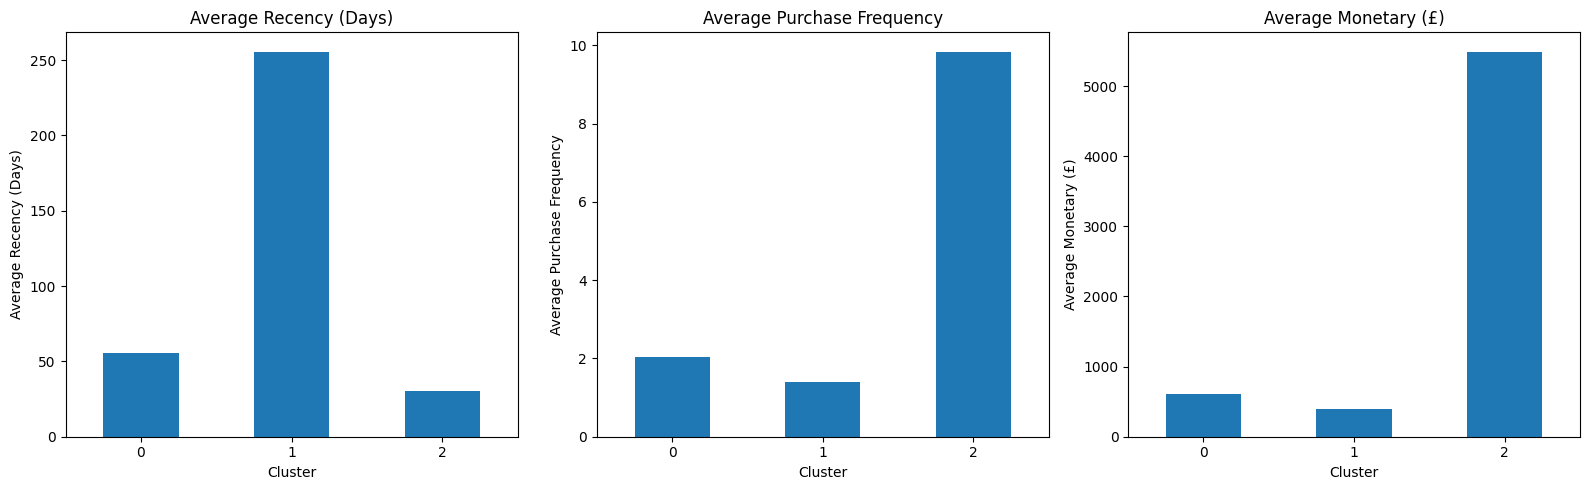

In [22]:
rfm_means = (
    rfm_clustered.groupby('Cluster')[
        ['Recency', 'Frequency', 'Monetary']
    ]
    .mean()
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = [
    ('Recency', 'Average Recency (Days)'),
    ('Frequency', 'Average Purchase Frequency'),
    ('Monetary', 'Average Monetary (£)')
]

for ax, (column, title) in zip(axes, metrics):
    rfm_means[column].plot(
        kind='bar',
        ax=ax,
        rot=0
    )
    ax.set_title(title)
    ax.set_xlabel('Cluster')
    ax.set_ylabel(title)

plt.tight_layout()
plt.show()

### 3.2 Pemeriksaan Nilai Ekstrem pada Setiap Cluster

Rata-rata Monetary pada Cluster 2 terlihat jauh lebih tinggi dibandingkan cluster lainnya. Perbedaan ini dapat mencerminkan karakteristik pelanggan bernilai tinggi, tetapi juga mungkin dipengaruhi oleh sejumlah pelanggan dengan nilai pembelian ekstrem.

Oleh karena itu, pemeriksaan dilakukan dengan membandingkan rata-rata dan median Recency, Frequency, serta Monetary pada setiap cluster, kemudian mengidentifikasi pelanggan dengan nilai Monetary tertinggi. Pemeriksaan ini bertujuan memahami distribusi data dan pengaruh nilai ekstrem terhadap interpretasi cluster, bukan untuk langsung menghapus pelanggan dari dataset.

In [23]:
cluster_distribution = (
    rfm_clustered.groupby('Cluster')
    .agg(
        Jumlah_Pelanggan=('CustomerID', 'count'),
        Mean_Recency=('Recency', 'mean'),
        Median_Recency=('Recency', 'median'),
        Mean_Frequency=('Frequency', 'mean'),
        Median_Frequency=('Frequency', 'median'),
        Mean_Monetary=('Monetary', 'mean'),
        Median_Monetary=('Monetary', 'median')
    )
    .round(2)
)

display(cluster_distribution)

,Jumlah_Pelanggan,Mean_Recency,Median_Recency,Mean_Frequency,Median_Frequency,Mean_Monetary,Median_Monetary
Cluster,,,,,,,
0,2038,55.31,46.0,2.05,2.0,612.67,508.80
1,980,255.70,253.0,1.39,1.0,397.03,290.46
2,1320,30.60,18.0,9.84,7.0,5492.04,2570.50


In [24]:
top_monetary_customers = (
    rfm_clustered[
        ['CustomerID', 'Cluster', 'Recency', 'Frequency', 'Monetary']
    ]
    .sort_values('Monetary', ascending=False)
    .head(10)
)

display(top_monetary_customers)

,CustomerID,Cluster,Recency,Frequency,Monetary
1689,14646.0,2,2,73,280206.02
4201,18102.0,2,1,60,259657.30
3728,17450.0,2,9,46,194390.79
3008,16446.0,2,1,2,168472.50
1879,14911.0,2,2,201,143711.17
55,12415.0,2,25,21,124914.53
1333,14156.0,2,10,55,117210.08
3771,17511.0,2,3,31,91062.38
2702,16029.0,2,39,63,80850.84
0,12346.0,2,326,1,77183.60


### 3.3 Identifikasi Kandidat Outlier Monetary dengan Metode IQR

Metode Interquartile Range (IQR) digunakan untuk mengidentifikasi kandidat outlier berdasarkan distribusi Monetary pada setiap cluster. IQR dihitung dari selisih kuartil ketiga (Q3) dan kuartil pertama (Q1).

Batas bawah ditentukan menggunakan Q1 − 1,5 × IQR, sedangkan batas atas ditentukan menggunakan Q3 + 1,5 × IQR. Pelanggan dengan nilai Monetary di luar batas tersebut ditandai sebagai kandidat outlier.

Perhitungan dilakukan secara terpisah pada setiap cluster agar karakteristik distribusi masing-masing kelompok tetap diperhatikan. Hasil identifikasi digunakan untuk memahami sebaran nilai pembelian, bukan sebagai dasar otomatis untuk menghapus pelanggan.

In [25]:
outlier_results = []

for cluster_id, group in rfm_clustered.groupby('Cluster'):
    q1 = group['Monetary'].quantile(0.25)
    q3 = group['Monetary'].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (group['Monetary'] < lower_bound) |
        (group['Monetary'] > upper_bound)
    )

    outlier_results.append({
        'Cluster': cluster_id,
        'Q1_Monetary': q1,
        'Q3_Monetary': q3,
        'IQR': iqr,
        'Batas_Bawah': lower_bound,
        'Batas_Atas': upper_bound,
        'Jumlah_Kandidat_Outlier': int(outlier_mask.sum()),
        'Persentase_Outlier': outlier_mask.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_results).round(2)

display(outlier_summary)

,Cluster,Q1_Monetary,Q3_Monetary,IQR,Batas_Bawah,Batas_Atas,Jumlah_Kandidat_Outlier,Persentase_Outlier
0,0,286.12,801.30,515.18,-486.66,1574.08,76,3.73
1,1,155.92,459.04,303.12,-298.75,913.72,78,7.96
2,2,1689.77,4303.42,2613.65,-2230.70,8223.89,130,9.85


### 3.4 Pemeriksaan Contoh Pelanggan Kandidat Outlier

Setelah mengidentifikasi kandidat outlier Monetary menggunakan metode IQR, pemeriksaan dilanjutkan dengan melihat beberapa pelanggan yang memiliki nilai Monetary di atas batas atas cluster masing-masing.

Pemeriksaan mencakup CustomerID, cluster, Recency, Frequency, dan Monetary. Informasi ini digunakan untuk memahami karakteristik pelanggan dengan nilai pembelian tinggi serta membedakan nilai ekstrem yang mungkin mencerminkan pola pembelian nyata dari kondisi yang memerlukan pemeriksaan data lebih lanjut.

Pelanggan yang teridentifikasi sebagai kandidat outlier tidak otomatis dianggap sebagai kesalahan data dan tidak dihapus pada tahap ini.

In [26]:
outlier_customers = []

for cluster_id, group in rfm_clustered.groupby('Cluster'):
    q1 = group['Monetary'].quantile(0.25)
    q3 = group['Monetary'].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr

    candidates = group[group['Monetary'] > upper_bound].copy()
    candidates['Batas_Atas_IQR'] = upper_bound

    outlier_customers.append(candidates)

outlier_customers = pd.concat(outlier_customers, ignore_index=True)

top_outliers = (
    outlier_customers
    .sort_values(
        ['Cluster', 'Monetary'],
        ascending=[True, False]
    )
    .groupby('Cluster')
    .head(5)
    .reset_index(drop=True)
)

display(
    top_outliers[
        [
            'CustomerID',
            'Cluster',
            'Recency',
            'Frequency',
            'Monetary',
            'Batas_Atas_IQR'
        ]
    ].round(2)
)

,CustomerID,Cluster,Recency,Frequency,Monetary,Batas_Atas_IQR
0,12357.0,0,34,1,6207.67,1574.08
1,12688.0,0,114,1,4873.81,1574.08
2,12752.0,0,82,1,4366.78,1574.08
3,18251.0,0,88,1,4314.72,1574.08
4,12378.0,0,130,1,4008.62,1574.08
5,15032.0,1,257,3,4959.10,913.72
6,12755.0,1,281,2,3811.95,913.72
7,15808.0,1,307,4,3651.27,913.72
8,13952.0,1,218,2,3251.07,913.72
9,13135.0,1,197,1,3096.00,913.72


### 3. Kesimpulan Pembangunan Model K-Means

Model K-Means dibangun menggunakan tiga fitur RFM, yaitu Recency, Frequency, dan Monetary, yang telah melalui transformasi dan standardisasi pada tahap preprocessing. Berdasarkan evaluasi awal menggunakan Elbow Method dan Silhouette Score, jumlah cluster sebanyak tiga dipilih sebagai kandidat utama. Konfigurasi ini menghasilkan Silhouette Score sebesar 0,4157, tertinggi di antara jumlah cluster yang diuji.

Hasil clustering membagi 4.338 pelanggan menjadi tiga kelompok:

- **Cluster 0: Moderate-Recency, Low-Frequency Customers.** Terdiri dari 2.038 pelanggan dengan rata-rata Recency 55,31 hari, Frequency 2,05 transaksi, dan Monetary £612,67.
- **Cluster 1: Long-Recency, Low-Frequency Customers.** Terdiri dari 980 pelanggan dengan rata-rata Recency 255,70 hari, Frequency 1,39 transaksi, dan Monetary £397,03.
- **Cluster 2: Recent, High-Frequency, High-Monetary Customers.** Terdiri dari 1.320 pelanggan dengan rata-rata Recency 30,60 hari, Frequency 9,84 transaksi, dan Monetary £5.492,04.

Pemeriksaan distribusi menunjukkan bahwa rata-rata dan median Monetary pada Cluster 2 memiliki perbedaan yang cukup besar. Pemeriksaan menggunakan metode Interquartile Range (IQR) juga mengidentifikasi kandidat outlier pada ketiga cluster, dengan persentase tertinggi pada Cluster 2 sebesar 9,85%.

Kandidat outlier tidak langsung dihapus karena nilai pembelian yang tinggi dapat mencerminkan aktivitas pelanggan yang nyata. Oleh karena itu, karakteristik RFM asli tetap digunakan untuk interpretasi hasil clustering, sedangkan fitur yang telah distandardisasi digunakan dalam pemodelan.

Secara keseluruhan, model menghasilkan tiga kelompok pelanggan dengan karakteristik RFM yang berbeda. Hasil ini menjadi dasar untuk tahap evaluasi kualitas cluster dan penarikan kesimpulan lebih lanjut mengenai segmentasi pelanggan.

## 4. Evaluasi dan Interpretasi Cluster



### 4.1 Evaluasi Model Menggunakan Silhouette Score

Silhouette Score digunakan untuk mengevaluasi kualitas hasil pengelompokan pelanggan menggunakan algoritma K-Means. Metrik ini mengukur seberapa dekat setiap pelanggan dengan anggota cluster-nya dibandingkan dengan cluster lain.

Nilai Silhouette Score berada pada rentang -1 hingga 1. Nilai yang mendekati 1 menunjukkan bahwa pelanggan cenderung berada pada cluster yang sesuai dan terpisah dengan baik dari cluster lain. Nilai yang mendekati 0 menunjukkan bahwa pelanggan berada di area perbatasan antarkelompok, sedangkan nilai negatif dapat mengindikasikan bahwa pelanggan lebih dekat dengan cluster lain.

Pada tahap ini, Silhouette Score dihitung untuk model K-Means dengan tiga cluster menggunakan fitur Recency, Frequency, dan Monetary yang telah distandardisasi. Hasilnya digunakan untuk menilai kualitas pemisahan cluster secara keseluruhan, bukan untuk menentukan manfaat bisnis secara langsung.

In [27]:
from sklearn.metrics import silhouette_score

# Mengambil fitur yang digunakan dalam model K-Means
X = rfm_modeling[['Recency', 'Frequency', 'Monetary']].copy()

# Menghitung Silhouette Score untuk model dengan 3 cluster
silhouette_final = silhouette_score(
    X,
    rfm_modeling['Cluster']
)

print('Jumlah cluster:', rfm_modeling['Cluster'].nunique())
print('Silhouette Score:', round(silhouette_final, 4))

Jumlah cluster: 3
Silhouette Score: 0.4157


**Interpretasi Hasil Silhouette Score**

Evaluasi model K-Means dengan tiga cluster menghasilkan Silhouette Score sebesar 0,4157. Nilai ini menunjukkan bahwa hasil pengelompokan memiliki pemisahan yang cukup terlihat, meskipun belum sepenuhnya terpisah dengan baik.

Hasil tersebut konsisten dengan evaluasi jumlah cluster sebelumnya, ketika nilai Silhouette Score tertinggi juga diperoleh pada tiga cluster. Dengan demikian, model ini digunakan untuk melanjutkan analisis karakteristik dan interpretasi segmen pelanggan.

Meskipun demikian, Silhouette Score hanya menggambarkan kualitas pengelompokan secara matematis. Kegunaan setiap segmen tetap perlu dinilai berdasarkan karakteristik RFM dan konteks bisnis yang relevan.

### 4.2 Interpretasi Karakteristik Cluster

Interpretasi cluster dilakukan untuk memahami perbedaan karakteristik pelanggan berdasarkan nilai Recency, Frequency, dan Monetary (RFM). Analisis menggunakan nilai RFM asli agar hasil pengelompokan dapat dijelaskan dalam satuan yang mudah dipahami.

Berdasarkan hasil clustering, terdapat tiga kelompok pelanggan dengan pola transaksi yang berbeda:

**Cluster 0: Moderate-Recency, Low-Frequency Customers**

Cluster ini terdiri dari 2.038 pelanggan atau sekitar 47,0% dari seluruh pelanggan. Rata-rata Recency sebesar 55,31 hari, Frequency sebanyak 2,05 transaksi, dan Monetary sebesar £612,67. Kelompok ini memiliki frekuensi pembelian relatif rendah dengan jarak transaksi terakhir yang berada di antara Cluster 1 dan Cluster 2.

**Cluster 1: Long-Recency, Low-Frequency Customers**

Cluster ini terdiri dari 980 pelanggan atau sekitar 22,6% dari seluruh pelanggan. Rata-rata Recency sebesar 255,70 hari, Frequency sebanyak 1,39 transaksi, dan Monetary sebesar £397,03. Kelompok ini memiliki jarak transaksi terakhir paling tinggi, frekuensi pembelian paling rendah, dan nilai pembelian rata-rata paling rendah di antara ketiga cluster.

**Cluster 2: Recent, High-Frequency, High-Monetary Customers**

Cluster ini terdiri dari 1.320 pelanggan atau sekitar 30,4% dari seluruh pelanggan. Rata-rata Recency sebesar 30,60 hari, Frequency sebanyak 9,84 transaksi, dan Monetary sebesar £5.492,04. Kelompok ini memiliki jarak transaksi terakhir paling rendah, frekuensi pembelian paling tinggi, dan nilai pembelian rata-rata paling tinggi di antara ketiga cluster.

Secara keseluruhan, ketiga cluster menunjukkan perbedaan pola transaksi yang cukup jelas. Cluster 0 didominasi pelanggan dengan frekuensi pembelian relatif rendah, Cluster 1 menunjukkan pelanggan yang cenderung sudah lama tidak bertransaksi, sedangkan Cluster 2 memiliki frekuensi dan nilai pembelian yang lebih tinggi.

Interpretasi ini bersifat deskriptif berdasarkan data historis. Hasil clustering tidak secara langsung membuktikan loyalitas pelanggan atau memprediksi perilaku pembelian di masa mendatang.

### 4.3 Visualisasi Persebaran Pelanggan Berdasarkan Cluster

Scatter plot digunakan untuk melihat persebaran pelanggan berdasarkan Recency dan Monetary. Setiap titik mewakili satu pelanggan, sedangkan warna menunjukkan cluster yang dihasilkan oleh model K-Means.

Recency ditampilkan pada sumbu X dan Monetary pada sumbu Y. Visualisasi ini membantu mengamati perbedaan pola transaksi antarkelompok, persebaran pelanggan dalam setiap cluster, serta kemungkinan tumpang tindih antara cluster.

Grafik menggunakan nilai RFM asli agar sumbu dapat diinterpretasikan dalam satuan hari dan pound sterling. Oleh karena itu, visualisasi ini digunakan untuk interpretasi hasil clustering, bukan untuk membangun ulang model.

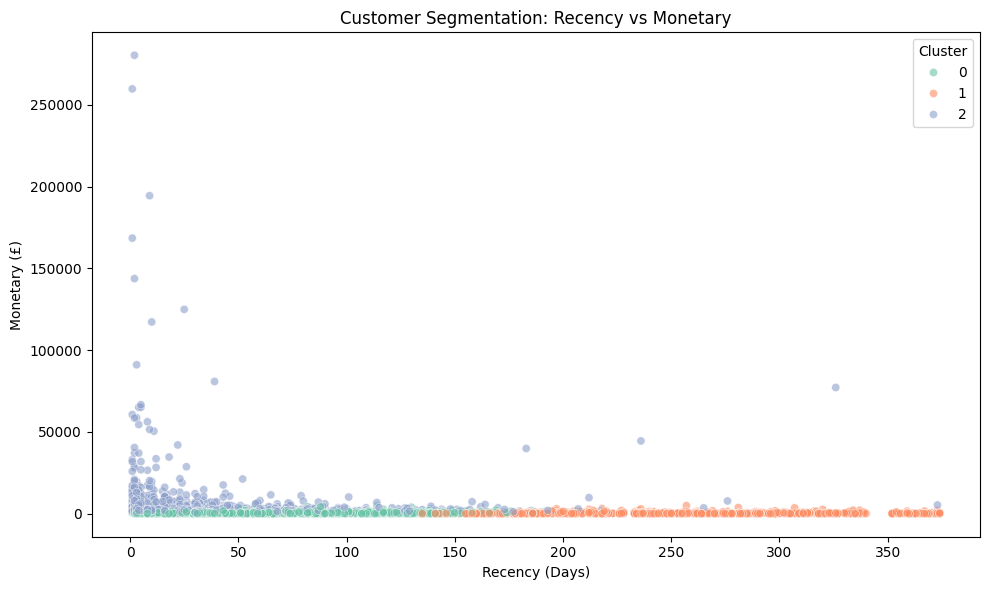

In [28]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm_clustered,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='Set2',
    alpha=0.6,
    s=35
)

plt.title('Customer Segmentation: Recency vs Monetary')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary (£)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

### 4.4 Visualisasi Interaktif 3D Berdasarkan Fitur Model

Visualisasi tiga dimensi digunakan untuk mengeksplorasi persebaran pelanggan berdasarkan fitur yang digunakan dalam model K-Means, yaitu Recency, Frequency, dan Monetary setelah transformasi dan standardisasi.

Setiap titik mewakili satu pelanggan, sedangkan warna menunjukkan cluster hasil pengelompokan. Visualisasi dibuat menggunakan Plotly agar grafik dapat diputar, diperbesar, dan dieksplorasi secara interaktif.

Berbeda dari visualisasi menggunakan nilai RFM asli, grafik ini menggunakan fitur yang telah diproses sehingga skala setiap sumbu lebih sebanding dan sesuai dengan representasi data yang digunakan saat pelatihan model. Nilai asli pelanggan tetap dapat dilihat melalui informasi tambahan ketika kursor diarahkan ke titik.

In [31]:
import plotly.express as px

rfm_3d = rfm_modeling[
    ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'Cluster']
].copy()

rfm_3d = rfm_3d.merge(
    rfm_original[
        ['CustomerID', 'Recency', 'Frequency', 'Monetary']
    ],
    on='CustomerID',
    how='inner',
    suffixes=('_Scaled', '_Original')
)

rfm_3d['Cluster_Label'] = (
    'Cluster ' + rfm_3d['Cluster'].astype(str)
)

fig = px.scatter_3d(
    rfm_3d,
    x='Recency_Scaled',
    y='Frequency_Scaled',
    z='Monetary_Scaled',
    color='Cluster_Label',
    hover_data={
        'CustomerID': True,
        'Recency_Original': True,
        'Frequency_Original': True,
        'Monetary_Original': ':.2f',
        'Cluster': True,
        'Recency_Scaled': False,
        'Frequency_Scaled': False,
        'Monetary_Scaled': False,
        'Cluster_Label': False
    },
    title='Interactive 3D Customer Segmentation',
    labels={
        'Recency_Scaled': 'Recency (Standardized)',
        'Frequency_Scaled': 'Frequency (Log + Standardized)',
        'Monetary_Scaled': 'Monetary (Log + Standardized)',
        'Cluster_Label': 'Customer Cluster'
    },
    opacity=0.7
)

fig.update_layout(
    scene=dict(
        xaxis_title='Recency (Standardized)',
        yaxis_title='Frequency (Log + Standardized)',
        zaxis_title='Monetary (Log + Standardized)'
    ),
    legend_title_text='Customer Cluster',
    height=700
)

fig.show()

## 5. Customer Segmentation Insights

Bagian ini membahas temuan utama dari hasil customer segmentation menggunakan K-Means. Analisis berfokus pada ukuran setiap segmen dan perbedaan karakteristik pelanggan berdasarkan Recency, Frequency, dan Monetary (RFM).

Hasil segmentasi digunakan untuk memahami pola transaksi pelanggan dan mengidentifikasi perbedaan nilai pembelian serta aktivitas transaksi antarsegmen. Interpretasi didasarkan pada nilai RFM asli, sedangkan label cluster berasal dari model K-Means.

Temuan pada bagian ini menjadi dasar untuk merumuskan implikasi bisnis yang sesuai dengan karakteristik masing-masing segmen. Interpretasi tetap dibatasi pada pola transaksi historis dan tidak dianggap sebagai prediksi pasti mengenai perilaku pelanggan di masa mendatang.

### 5.1 Ringkasan Profil Segmen Pelanggan

Ringkasan profil segmen digunakan untuk membandingkan ukuran dan karakteristik setiap cluster. Jumlah dan persentase pelanggan menunjukkan proporsi setiap segmen, sedangkan rata-rata RFM menggambarkan pola transaksi pelanggan dalam kelompok tersebut.

Tabel ini membantu mengidentifikasi perbedaan utama antarkelompok sebelum merumuskan insight dan implikasi bisnis.

In [32]:
segment_profile = (
    rfm_clustered.groupby('Cluster')
    .agg(
        Jumlah_Pelanggan=('CustomerID', 'count'),
        Rata_Rata_Recency=('Recency', 'mean'),
        Rata_Rata_Frequency=('Frequency', 'mean'),
        Rata_Rata_Monetary=('Monetary', 'mean')
    )
    .round(2)
)

segment_profile['Persentase_Pelanggan'] = (
    segment_profile['Jumlah_Pelanggan']
    / len(rfm_clustered)
    * 100
).round(2)

segment_profile = segment_profile[
    [
        'Jumlah_Pelanggan',
        'Persentase_Pelanggan',
        'Rata_Rata_Recency',
        'Rata_Rata_Frequency',
        'Rata_Rata_Monetary'
    ]
]

display(segment_profile)

,Jumlah_Pelanggan,Persentase_Pelanggan,Rata_Rata_Recency,Rata_Rata_Frequency,Rata_Rata_Monetary
Cluster,,,,,
0,2038,46.98,55.31,2.05,612.67
1,980,22.59,255.70,1.39,397.03
2,1320,30.43,30.60,9.84,5492.04


### 5.2 Insight Peluang Bisnis Berdasarkan Segmen Pelanggan

Hasil customer segmentation menunjukkan bahwa setiap cluster memiliki karakteristik transaksi yang berbeda. Perbedaan tersebut dapat digunakan untuk mengidentifikasi peluang bisnis yang berpotensi meningkatkan aktivitas pembelian dan mempertahankan nilai pelanggan.

**Cluster 0: Moderate-Recency, Low-Frequency Customers**

Cluster ini mencakup 2.038 pelanggan atau 46,98% dari keseluruhan pelanggan. Rata-rata Recency sebesar 55,31 hari, Frequency sebanyak 2,05 transaksi, dan Monetary sebesar £612,67.

Sebagai segmen terbesar, kelompok ini berpotensi menjadi sasaran upaya peningkatan frekuensi pembelian. Perusahaan dapat mengeksplorasi program promosi yang relevan atau rekomendasi produk berdasarkan riwayat pembelian untuk mendorong pelanggan melakukan transaksi kembali. Namun, efektivitas pendekatan tersebut perlu diuji sebelum diterapkan secara luas.

**Cluster 1: Long-Recency, Low-Frequency Customers**

Cluster ini mencakup 980 pelanggan atau 22,59% dari keseluruhan pelanggan. Rata-rata Recency sebesar 255,70 hari, Frequency sebanyak 1,39 transaksi, dan Monetary sebesar £397,03.

Kelompok ini menunjukkan aktivitas pembelian yang relatif rendah dan jarak transaksi terakhir yang lebih panjang dibandingkan cluster lainnya. Peluang bisnis yang dapat dieksplorasi adalah kampanye reaktivasi pelanggan, misalnya melalui penawaran yang relevan atau pengingat produk. Sebelum menerapkan kampanye, perusahaan perlu mengevaluasi apakah biaya reaktivasi sebanding dengan potensi nilai pembelian pelanggan.

**Cluster 2: Recent, High-Frequency, High-Monetary Customers**

Cluster ini mencakup 1.320 pelanggan atau 30,43% dari keseluruhan pelanggan. Rata-rata Recency sebesar 30,60 hari, Frequency sebanyak 9,84 transaksi, dan Monetary sebesar £5.492,04.

Kelompok ini memiliki frekuensi dan nilai pembelian rata-rata tertinggi. Peluang bisnis yang dapat dieksplorasi adalah mempertahankan pengalaman pembelian yang baik, memberikan rekomendasi produk yang relevan, dan mengevaluasi program penghargaan pelanggan. Karena rata-rata Monetary cukup jauh di atas median, perusahaan juga perlu mempertimbangkan variasi nilai pelanggan sebelum merancang program yang sama untuk seluruh anggota cluster.

**Ringkasan Peluang Bisnis**

Hasil segmentasi menunjukkan tiga arah peluang yang berbeda: meningkatkan frekuensi pembelian pada Cluster 0, mengeksplorasi reaktivasi pada Cluster 1, dan mempertahankan aktivitas pembelian bernilai tinggi pada Cluster 2. Peluang tersebut merupakan hipotesis awal berdasarkan transaksi historis, bukan bukti bahwa strategi tertentu pasti meningkatkan pendapatan.

### 5.3 Rekomendasi Tindakan per Segmen Pelanggan

Berdasarkan karakteristik RFM setiap cluster, rekomendasi tindakan disusun dengan mempertimbangkan pola transaksi dan peluang bisnis yang dapat diuji. Rekomendasi ini merupakan usulan awal, sehingga efektivitasnya perlu dievaluasi menggunakan data hasil kampanye atau eksperimen sebelum diterapkan secara luas.

**Cluster 0: Moderate-Recency, Low-Frequency Customers**

**Karakteristik:** Segmen terbesar, mencakup 46,98% pelanggan, dengan rata-rata Frequency 2,05 transaksi dan Monetary £612,67.

**Rekomendasi tindakan:** Menguji promosi yang relevan atau rekomendasi produk berdasarkan riwayat pembelian untuk mendorong pembelian berulang. Perusahaan dapat memulai dengan sebagian pelanggan untuk melihat apakah pendekatan tersebut meningkatkan frekuensi transaksi tanpa memberikan diskon yang berlebihan.

**Metrik evaluasi:** Tingkat pembelian ulang, rata-rata frekuensi transaksi, dan pendapatan per pelanggan setelah kampanye.

**Cluster 1: Long-Recency, Low-Frequency Customers**

**Karakteristik:** Mencakup 22,59% pelanggan, dengan rata-rata Recency 255,70 hari, Frequency 1,39 transaksi, dan Monetary £397,03.

**Rekomendasi tindakan:** Menguji kampanye reaktivasi, seperti pengingat produk atau penawaran yang relevan bagi pelanggan yang sudah lama tidak bertransaksi. Pengujian sebaiknya membandingkan kelompok yang menerima kampanye dengan kelompok kontrol untuk mengetahui apakah kampanye benar-benar mendorong pembelian kembali.

**Metrik evaluasi:** Tingkat pelanggan yang kembali bertransaksi, pendapatan dari pelanggan yang berhasil diaktifkan kembali, dan biaya kampanye per pelanggan yang kembali membeli.

**Cluster 2: Recent, High-Frequency, High-Monetary Customers**

**Karakteristik:** Mencakup 30,43% pelanggan, dengan rata-rata Frequency 9,84 transaksi dan Monetary £5.492,04. Segmen ini memiliki rata-rata nilai pembelian tertinggi di antara ketiga cluster.

**Rekomendasi tindakan:** Menjaga pengalaman pembelian dan mengevaluasi program penghargaan pelanggan atau rekomendasi produk yang relevan. Mengingat perbedaan nilai Monetary di dalam cluster, program sebaiknya dirancang dengan mempertimbangkan variasi nilai pelanggan, bukan menganggap seluruh anggota memiliki potensi yang sama.

**Metrik evaluasi:** Tingkat pelanggan yang tetap aktif, frekuensi pembelian, pendapatan per pelanggan, dan margin setelah biaya program.

**Catatan Evaluasi Rekomendasi**

Keberhasilan rekomendasi tidak dapat disimpulkan hanya dari hasil clustering. Perusahaan perlu mengukur perubahan metrik setelah tindakan dilakukan dan, jika memungkinkan, membandingkan hasilnya dengan kelompok kontrol. Pendekatan ini membantu membedakan perubahan yang berkaitan dengan kampanye dari pola pembelian yang memang terjadi secara alami.

## 6. Kesimpulan Customer Segmentation

Berdasarkan hasil analisis RFM dan penerapan algoritma K-Means, sebanyak 4.338 pelanggan berhasil dikelompokkan menjadi tiga segmen berdasarkan Recency, Frequency, dan Monetary. Jumlah cluster ditentukan menggunakan perbandingan Elbow Method dan Silhouette Score. Pada pengujian kandidat 2 hingga 10 cluster, nilai Silhouette Score tertinggi diperoleh pada \(k = 3\), yaitu sebesar 0,4157.

Hasil segmentasi menunjukkan tiga karakteristik pelanggan:

1. **Cluster 0: Moderate-Recency, Low-Frequency Customers.** Segmen terbesar dengan 2.038 pelanggan (46,98%). Pelanggan memiliki rata-rata Recency 55,31 hari, Frequency 2,05 transaksi, dan Monetary £612,67. Segmen ini berpotensi dikembangkan melalui promosi yang relevan untuk mendorong pembelian berulang.
2. **Cluster 1: Long-Recency, Low-Frequency Customers.** Terdiri dari 980 pelanggan (22,59%). Segmen ini memiliki rata-rata Recency 255,70 hari, Frequency 1,39 transaksi, dan Monetary £397,03. Pelanggan dalam segmen ini dapat menjadi sasaran awal kampanye aktivasi kembali, dengan tetap mengevaluasi biaya dan hasilnya.
3. **Cluster 2: Recent, High-Frequency, High-Monetary Customers.** Terdiri dari 1.320 pelanggan (30,43%). Segmen ini memiliki rata-rata Recency 30,60 hari, Frequency 9,84 transaksi, dan Monetary £5.492,04. Segmen ini menunjukkan nilai transaksi kumulatif dan frekuensi pembelian yang relatif tinggi sehingga layak dipertimbangkan dalam strategi mempertahankan pelanggan.

Tahapan preprocessing, meliputi transformasi log pada Frequency dan Monetary serta standardisasi fitur, membantu menyamakan skala fitur sebelum clustering. Pemeriksaan nilai ekstrem juga menunjukkan bahwa terdapat pelanggan dengan nilai Monetary yang jauh lebih tinggi dibandingkan pelanggan lain. Nilai tersebut tidak langsung dihapus karena masih perlu diperiksa berdasarkan konteks transaksi.

Secara bisnis, hasil segmentasi dapat digunakan sebagai dasar untuk menyusun strategi pemasaran yang berbeda bagi setiap kelompok pelanggan. Namun, hasil clustering belum membuktikan bahwa strategi tertentu akan meningkatkan penjualan atau retensi. Efektivitas rekomendasi perlu diuji menggunakan data setelah kampanye dijalankan dan, jika memungkinkan, dibandingkan dengan kelompok kontrol.

**Keterbatasan analisis:** Dataset mencakup transaksi Desember 2010 hingga Desember 2011, sehingga hasilnya menggambarkan perilaku pelanggan pada periode historis tersebut. Selain itu, analisis menggunakan data transaksi dengan CustomerID yang tersedia dan memisahkan transaksi pembatalan dari dataset utama. Karena itu, hasil pendapatan yang digunakan dalam analisis tidak dapat langsung dianggap sebagai pendapatan bersih akuntansi.

Secara keseluruhan, proyek ini menunjukkan penerapan proses analisis data dari pembersihan data, eksplorasi, pembentukan fitur RFM, preprocessing, pemodelan K-Means, hingga penerjemahan hasil model menjadi rekomendasi bisnis.